# Tesla ya importa más que Toyota: qué está comprando Colombia en 2026

Análisis del newsletter de Croma, número 1 (octubre de 2026). Todo sale de fuentes oficiales consultadas con la [API de Croma](https://usecroma.com):

- **Directorio de importadores de la DIAN**, 2017 a 2026 (2026 hasta agosto). Valores CIF en dólares, por empresa (NIT).
- **VUCE**, consulta de arancel y vistos buenos de importación, por subpartida.

**Cómo correrlo.** Con `CROMA_API_KEY` en el entorno, el notebook consulta la API y actualiza los CSV de `data/`. Sin llave, lee esos CSV, que son la foto de los datos usada en el artículo (consultada el 29 de octubre de 2026).

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
import croma

DATA = Path("data")
CHARTS = Path("charts")
DATA.mkdir(exist_ok=True)
CHARTS.mkdir(exist_ok=True)
ONLINE = croma.has_key()
print("Consultando la API de Croma" if ONLINE else "Sin CROMA_API_KEY: leyendo los CSV de data/")

pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
M = 1e6  # millones de USD

Consultando la API de Croma


## Los mayores importadores de 2026 y de 2025

`/co/dian-trade/directory-search/v1` devuelve el directorio por año, ordenado por valor. Tomamos los 100 primeros de cada año.

In [2]:
COLUMNS = ["year", "through_month", "rank", "document_number", "name", "value_usd", "declarations", "top_tariff_codes"]


def top_importers(year: int) -> pd.DataFrame:
    path = DATA / f"importadores-{year}-top100.csv"
    if ONLINE:
        rows = croma.search_all("/co/dian-trade/directory-search/v1", max_pages=1, flow="import", year=year, per_page=100)
        df = pd.DataFrame(rows)
        df = df[~df.natural_person][COLUMNS]  # solo empresas: las personas naturales no se publican
        df["top_tariff_codes"] = df["top_tariff_codes"].map(" ".join)
        df.to_csv(path, index=False)
    return pd.read_csv(path, dtype={"document_number": str})


top_2026 = top_importers(2026)
top_2025 = top_importers(2025)
top_2026.assign(millones_usd=top_2026.value_usd / M)[["rank", "name", "millones_usd", "declarations"]].head(10)

,rank,name,millones_usd,declarations
0,1,ECOPETROL S A,"2,744.6",1772
1,2,CALAMARI LNG S.A E.S.P,929.3,98
2,3,COLOMBIANA DE COMERCIO SA CORBETA YO ALKOSTO,816.0,39806
3,4,REFINERIA DE CARTAGENA S.A.S,690.1,74
4,5,TESLA MOTORS COLOMBIA S. A. S.,633.8,2819
5,6,AUTOMOTORES TOYOTA COLOMBIA SAS,608.0,24984
6,7,SAMSUNG ELECTRONICS COLOMBIA S.A.,538.7,12989
7,8,METROKIA S.A.,476.3,7325
8,9,MAZDA DE COLOMBIA S.A.S.,367.2,10194
9,10,RENAULT SOCIEDAD DE FABRICACION DE AUTOMOTORES...,347.1,19839


## 1. Tesla: del puesto 1.351 al 5

`/co/dian-trade/profile/v1` devuelve la historia de una empresa por NIT, todos los años en que aparece en el directorio.

In [3]:
COMPANIES = {
    "901789698": "Tesla Motors Colombia",
    "900851785": "Calamari LNG",
    "900597369": "BYD Motor Colombia",
    "900780510": "Toyota",
    "830028931": "Samsung Electronics",
    "900736182": "Apple",
    "890900943": "Alkosto (Colombiana de Comercio)",
    "899999068": "Ecopetrol",
}


def history() -> pd.DataFrame:
    path = DATA / "historia-importaciones.csv"
    if ONLINE:
        rows = []
        for nit, label in COMPANIES.items():
            profile = croma.call("/co/dian-trade/profile/v1", document_number=nit)
            for row in profile["imports"]:
                rows.append({"empresa": label, "document_number": nit, "year": row["year"], "through_month": row["through_month"], "rank": row["rank"], "value_usd": row["value_usd"]})
        pd.DataFrame(rows).to_csv(path, index=False)
    return pd.read_csv(path, dtype={"document_number": str})


hist = history()
by_year = hist.pivot_table(index="empresa", columns="year", values="value_usd") / M
by_year[[2024, 2025, 2026]].round(1)

year,2024,2025,2026
empresa,,,
Alkosto (Colombiana de Comercio),744.4,931.9,816.0
Apple,417.3,475.3,236.7
BYD Motor Colombia,8.7,16.1,47.2
Calamari LNG,945.4,779.2,929.3
Ecopetrol,"3,935.8","3,322.7","2,744.6"
Samsung Electronics,700.0,753.8,538.7
Tesla Motors Colombia,NaN,6.8,633.8
Toyota,725.6,703.1,608.0


In [4]:
tesla = hist[hist.empresa == "Tesla Motors Colombia"].set_index("year")
print(f"2025: USD {tesla.loc[2025, 'value_usd'] / M:,.1f} millones, puesto {tesla.loc[2025, 'rank']}")
print(f"2026 (ene-ago): USD {tesla.loc[2026, 'value_usd'] / M:,.1f} millones, puesto {tesla.loc[2026, 'rank']}")
print(f"Veces lo de 2025: {tesla.loc[2026, 'value_usd'] / tesla.loc[2025, 'value_usd']:.1f}")

2025: USD 6.8 millones, puesto 1351
2026 (ene-ago): USD 633.8 millones, puesto 5
Veces lo de 2025: 93.3


### Los otros importadores de carros eléctricos

Filtramos el directorio por la subpartida 8703.80 (vehículos propulsados únicamente con motor eléctrico): aparecen las empresas que la tienen entre sus cinco principales. Comparamos 2025 con lo que llevan en 2026.

In [5]:
def ev_importers(year: int) -> pd.DataFrame:
    path = DATA / f"importadores-electricos-870380-{year}.csv"
    if ONLINE:
        rows = croma.search_all("/co/dian-trade/directory-search/v1", max_pages=3, flow="import", year=year, tariff_code="870380", per_page=100)
        df = pd.DataFrame(rows)
        df = df[~df.natural_person][COLUMNS]  # solo empresas: las personas naturales no se publican
        df["top_tariff_codes"] = df["top_tariff_codes"].map(" ".join)
        df.to_csv(path, index=False)
    return pd.read_csv(path, dtype={"document_number": str})


ev = ev_importers(2025)[["document_number", "name", "value_usd"]].merge(
    ev_importers(2026)[["document_number", "value_usd"]], on="document_number", suffixes=("_2025", "_2026")
)
ev["veces"] = ev.value_usd_2026 / ev.value_usd_2025
ev[ev.value_usd_2026 > ev.value_usd_2025].assign(
    m_2025=lambda d: d.value_usd_2025 / M, m_2026=lambda d: d.value_usd_2026 / M
).sort_values("m_2026", ascending=False)[["name", "m_2025", "m_2026", "veces"]].head(10)

,name,m_2025,m_2026,veces
11,TESLA MOTORS COLOMBIA S. A. S.,6.8,633.8,93.3
8,DISTRIBUIDORA LOS AUTOS DE COLOMBIA SAS,33.6,83.1,2.5
4,AUTOVARDI SAS,60.1,80.7,1.3
7,COM AUTOMOTRIZ SA,42.6,79.9,1.9
9,AUTOELITE SAS,18.4,19.4,1.1
10,GRUPO AUTOMOTRIZ CARRERA S.A.S,16.7,19.3,1.2
13,INVERSIONES 55 CAPITAL S.A.S.,5.9,7.0,1.2
15,FZ PRESTIGE SAS,4.7,5.6,1.2
16,AMBACAR COLOMBIA S.A.S,3.6,5.4,1.5
19,BUSINESS RB S.A.S.,2.6,4.2,1.6


### Qué pide la VUCE para importar un carro eléctrico

`/co/vuce/tariff/v1` devuelve el régimen, si requiere licencia previa y cada entidad que debe dar visto bueno, con su requisito y la norma que lo respalda.

In [6]:
def vuce(code: str) -> dict:
    path = DATA / f"vuce-{code}.json"
    if ONLINE:
        path.write_text(json.dumps(croma.call("/co/vuce/tariff/v1", tariff_code=code), ensure_ascii=False, indent=2))
    return json.loads(path.read_text())["tariff"]


electrico = vuce("8703809000")
print(electrico["description"], "| régimen:", electrico["import_regime"], "| licencia previa:", electrico["requires_import_license"])
pd.DataFrame(electrico["approvals"])[["authority_name", "prior_requirement", "marginal_notes"]]

Los demás vehículos automoviles, propulsados únicamente con motor électrico. | régimen: LIBRE | licencia previa: False


,authority_name,prior_requirement,marginal_notes
0,Ministerio de Transporte,FTH,Únicamente cuando se destinen al servicio públ...
1,Superintendencia de Vigilancia y Seguridad Pri...,RR o CVB o VB,Únicamente cuando sean blindados o con protecc...
2,Instituto Colombiano Agropecuario (ICA),DRFI,Aplica para usados
3,Autoridad Nacional de Licencias Ambientales (A...,CEPD y visto bueno por Protoclo de Montreal,Excepción: Cuando NO cuente con sistemas de re...


## 2. Colombia importa cada vez más gas

Calamari LNG importa gas natural licuado (subpartida 2711.11). Su historia en el directorio:

In [7]:
calamari = hist[hist.empresa == "Calamari LNG"].sort_values("year")
calamari.assign(millones_usd=calamari.value_usd / M)[["year", "through_month", "rank", "millones_usd"]]

,year,through_month,rank,millones_usd
11,2017,12,582,11.9
10,2018,12,56,123.7
9,2019,12,153,57.0
8,2020,12,128,59.9
7,2021,12,369,27.9
6,2022,12,157,84.9
5,2023,12,9,440.9
4,2024,12,2,945.4
3,2025,12,3,779.2
2,2026,8,2,929.3


In [8]:
gas = vuce("2711110000")
print(gas["description"], "| régimen:", gas["import_regime"])
pd.DataFrame(gas["approvals"])[["authority_name", "description"]]

Gas natural | régimen: LIBRE


,authority_name,description
0,Ministerio de Minas y Energía,Gas Natural Licuado


## 3. Lo que sube y lo que baja

Ocho meses son dos tercios del año: una empresa que en agosto ya lleva más del 67% de lo que importó en 2025 va al ritmo del año pasado o por encima. Las importaciones suelen subir antes de diciembre, así que es una aproximación, no una proyección.

In [9]:
pace = by_year[[2025, 2026]].dropna()
pace["pct_de_2025"] = pace[2026] / pace[2025] * 100
pace.sort_values("pct_de_2025", ascending=False).round(1)

year,2025,2026,pct_de_2025
empresa,,,
Tesla Motors Colombia,6.8,633.8,"9,331.5"
BYD Motor Colombia,16.1,47.2,293.0
Calamari LNG,779.2,929.3,119.3
Alkosto (Colombiana de Comercio),931.9,816.0,87.6
Toyota,703.1,608.0,86.5
Ecopetrol,"3,322.7","2,744.6",82.6
Samsung Electronics,753.8,538.7,71.5
Apple,475.3,236.7,49.8


### Maíz y soya entre los grandes importadores

Empresas del top 25 de 2026 cuyas principales subpartidas son maíz (1005) o torta de soya (2304), la materia prima del alimento para animales.

In [10]:
feed = top_2026.head(25)
feed[feed.top_tariff_codes.str.contains("1005|2304")].assign(millones_usd=lambda d: d.value_usd / M)[["rank", "name", "millones_usd", "top_tariff_codes"]]

,rank,name,millones_usd,top_tariff_codes
10,11,ITALCOL S.A,344.0,1005901100 2304000000 1201900000 2303300000 84...
16,17,PRODUCTORA DE ALIMENTOS CONCENTRADOS PARA ANIM...,257.9,1005901100 2304000000 2303300000 1201900000 23...
21,22,ITALCOL DE OCCIDENTE S.A.,236.0,1005901100 2304000000 1201900000 2303300000 23...
24,25,ALIMENTOS FINCA S.A.S.,226.6,1005901100 2304000000 2303300000 1201900000 23...


## Gráficas

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

SURFACE, TEXT, TEXT_2, MUTED, NEUTRAL, S1, S2 = "#1a1a19", "#f0efec", "#c3c2b7", "#8a8980", "#55544f", "#3987e5", "#d95926"
plt.rcParams.update({"axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "axes.edgecolor": SURFACE, "text.color": TEXT, "xtick.color": TEXT_2, "ytick.color": TEXT_2, "font.size": 13})
SOURCE = "Fuente: DIAN, directorio de importadores, vía Croma. Valor CIF en USD."


def es(v: float, decimals: int = 0) -> str:
    return f"{v:,.{decimals}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def finish(fig, ax, title, subtitle, name):
    ax.spines[:].set_visible(False)
    fig.text(0.04, 0.95, title, fontsize=20, color=TEXT, va="top")
    fig.text(0.04, 0.895, subtitle, fontsize=13, color=TEXT_2, va="top")
    fig.text(0.04, 0.03, SOURCE, fontsize=10.5, color=MUTED)
    fig.text(0.96, 0.03, "usecroma.com", fontsize=10.5, color=MUTED, ha="right")
    fig.savefig(CHARTS / name, dpi=200)
    plt.show()

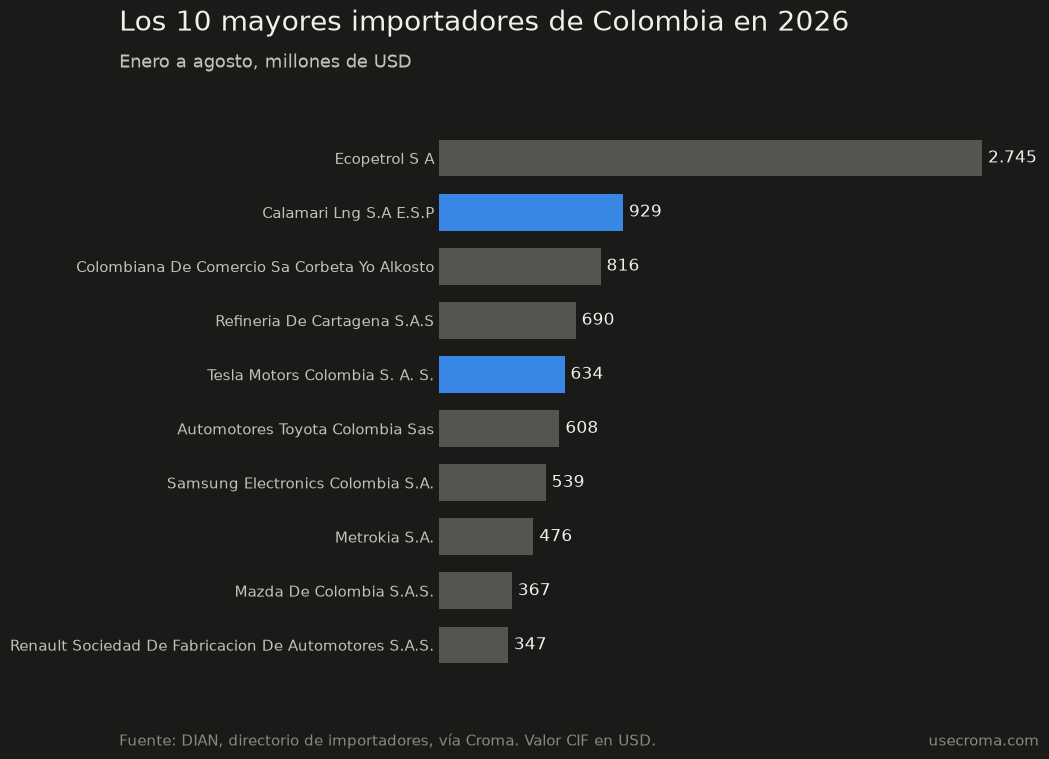

In [12]:
top10 = top_2026.head(10).iloc[::-1]
highlight = {"901789698", "900851785"}
fig, ax = plt.subplots(figsize=(10, 8))
fig.subplots_adjust(left=0.36, right=0.93, top=0.82, bottom=0.1)
ax.barh(top10.name.str.title(), top10.value_usd / M, color=[S1 if n in highlight else NEUTRAL for n in top10.document_number], height=0.68)
for y, v in enumerate(top10.value_usd / M):
    ax.text(v + 30, y, es(v), va="center", fontsize=12, color=TEXT)
ax.xaxis.set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
finish(fig, ax, "Los 10 mayores importadores de Colombia en 2026", "Enero a agosto, millones de USD", "01-top-importadores-2026.png")

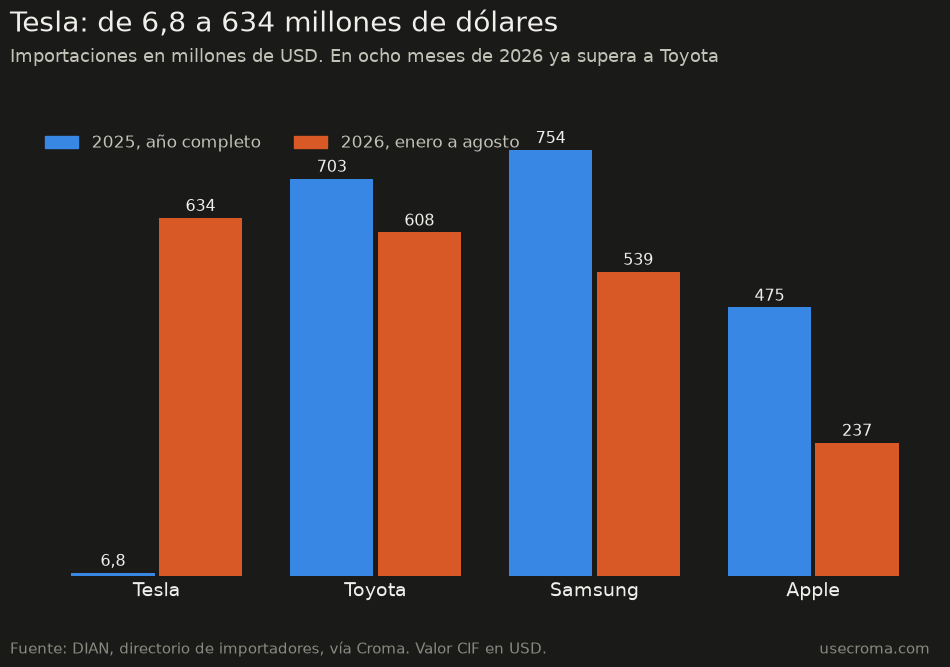

In [13]:
names = ["Tesla Motors Colombia", "Toyota", "Samsung Electronics", "Apple"]
y25 = [by_year.loc[n, 2025] for n in names]
y26 = [by_year.loc[n, 2026] for n in names]
x = range(len(names))
fig, ax = plt.subplots(figsize=(10, 7))
fig.subplots_adjust(left=0.06, right=0.97, top=0.78, bottom=0.14)
ax.bar([i - 0.2 for i in x], y25, 0.38, color=S1)
ax.bar([i + 0.2 for i in x], y26, 0.38, color=S2)
for i, (a, b) in enumerate(zip(y25, y26)):
    ax.text(i - 0.2, a + 12, es(a, 1 if a < 10 else 0), ha="center", fontsize=11.5, color=TEXT)
    ax.text(i + 0.2, b + 12, es(b), ha="center", fontsize=11.5, color=TEXT)
ax.set_xticks(list(x), ["Tesla", "Toyota", "Samsung", "Apple"], fontsize=14, color=TEXT)
ax.tick_params(axis="x", length=0)
ax.yaxis.set_visible(False)
ax.legend(handles=[Patch(color=S1, label="2025, año completo"), Patch(color=S2, label="2026, enero a agosto")], loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2, frameon=False, fontsize=12, labelcolor=TEXT_2)
finish(fig, ax, f"Tesla: de {es(y25[0], 1)} a {es(y26[0])} millones de dólares", "Importaciones en millones de USD. En ocho meses de 2026 ya supera a Toyota", "02-tesla-vs-otros.png")

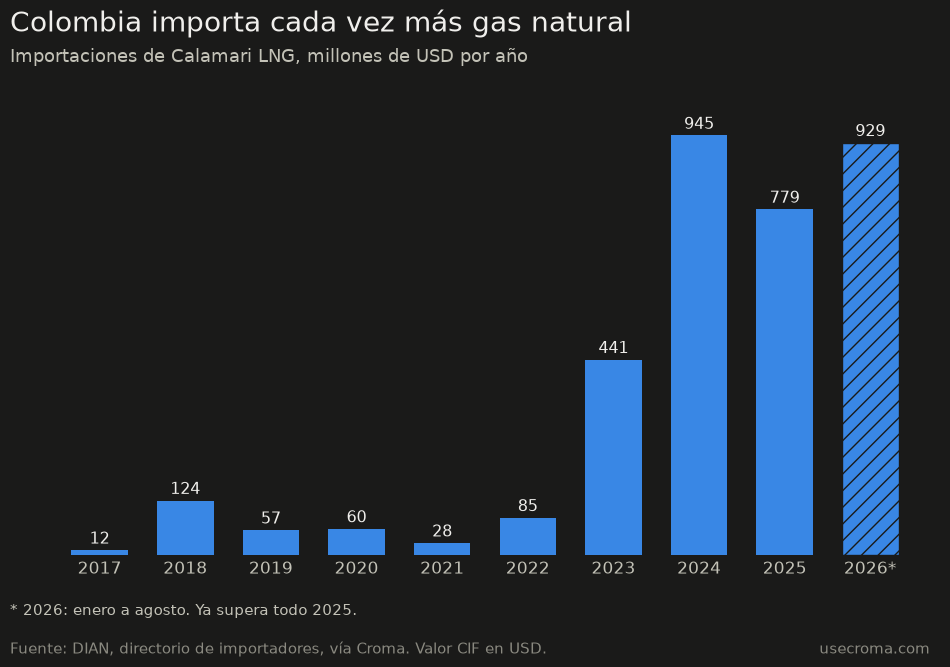

In [14]:
years = calamari.year.astype(int).tolist()
values = (calamari.value_usd / M).tolist()
labels = [f"{y}*" if y == 2026 else str(y) for y in years]
fig, ax = plt.subplots(figsize=(10, 7))
fig.subplots_adjust(left=0.06, right=0.97, top=0.8, bottom=0.17)
bars = ax.bar(labels, values, color=S1, width=0.66)
bars[-1].set_hatch("//")
bars[-1].set_edgecolor(SURFACE)
for i, v in enumerate(values):
    ax.text(i, v + 15, es(v), ha="center", fontsize=11.5, color=TEXT)
ax.yaxis.set_visible(False)
ax.tick_params(axis="x", length=0, labelsize=12.5)
fig.text(0.04, 0.085, "* 2026: enero a agosto. Ya supera todo 2025.", fontsize=11, color=TEXT_2)
finish(fig, ax, "Colombia importa cada vez más gas natural", "Importaciones de Calamari LNG, millones de USD por año", "03-gas-natural-calamari.png")

---

*Croma es un API | MCP que conecta más de 300 fuentes oficiales de gobierno en 9 países. Documentación: [docs.usecroma.com](https://docs.usecroma.com). ¿Qué quieren que analicemos en el próximo número? Abran un issue en este repo.*